In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "data").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent

MODELS_DIR = PROJECT_ROOT / "models"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"

MIN_SERIOUS_REPORTS = 300

bundle = joblib.load(MODELS_DIR / "serious_best_model.joblib")
config = json.loads((MODELS_DIR / "serious_feature_config.json").read_text())

model = bundle["model"]
FEATURES = bundle["feature_columns"]
TARGET = bundle["target"]
THRESHOLD = bundle["threshold"]

test = pd.read_parquet(PROCESSED_DATA_DIR / "serious_test.parquet")
X_test = test[FEATURES]
y_test = test[TARGET].to_numpy() == 1

probabilities = model.predict_proba(X_test)[:, 1]
predicted = probabilities >= THRESHOLD

print(f"Model: {bundle['model_name']}, threshold {THRESHOLD}")
print(f"Test reports: {len(test):,}")

Model: XGBoost, threshold 0.5
Test reports: 77,356


In [2]:
labels = {
    "age_years": "Age",
    "age_missing": "Age not reported",
    "sex_F": "Female",
    "sex_M": "Male",
    "sex_Unknown": "Sex not reported",
    "n_drugs": "Number of drugs",
    "n_other_drugs": "Unlisted drugs",
    "n_reactions": "Number of reactions",
    "n_other_reactions": "Unlisted reactions",
}

for name, col in zip(config["ingredients"], config["ingredient_columns"]):
    labels[col] = name.replace("\\", " + ").title()

for name, col in zip(config["reactions"], config["reaction_columns"]):
    labels[col] = f"Reaction: {name}"

assert set(FEATURES) <= set(labels), "Every feature needs a readable name"

In [3]:
missed = y_test & ~predicted
false_alarm = ~y_test & predicted

outcomes = pd.DataFrame(
    {
        "reports": [
            (y_test & predicted).sum(),
            missed.sum(),
            false_alarm.sum(),
            (~y_test & ~predicted).sum(),
        ]
    },
    index=[
        "Serious, caught",
        "Serious, missed",
        "Non-serious, false alarm",
        "Non-serious, correct",
    ],
)
outcomes["share_of_test"] = (outcomes["reports"] / len(test)).round(3)

display(outcomes)
print(f"Missed {missed.sum():,} of {y_test.sum():,} serious reports ({missed.sum() / y_test.sum():.1%})")

,reports,share_of_test
"Serious, caught",38110,0.493
"Serious, missed",4152,0.054
"Non-serious, false alarm",5039,0.065
"Non-serious, correct",30055,0.389


Missed 4,152 of 42,262 serious reports (9.8%)


In [4]:
serious = test[y_test].copy()
serious["missed"] = missed[y_test]


def miss_rate_by(groups):
    rows = []
    for name, mask in groups.items():
        rows.append({
            "group": name,
            "serious_reports": int(mask.sum()),
            "missed": int(serious.loc[mask, "missed"].sum()),
            "miss_rate": serious.loc[mask, "missed"].mean(),
        })
    return pd.DataFrame(rows).set_index("group")


n_reactions = serious["n_reactions"]

by_reactions = miss_rate_by({
    "1 reaction": n_reactions == 1,
    "2 reactions": n_reactions == 2,
    "3-4 reactions": n_reactions.between(3, 4),
    "5+ reactions": n_reactions >= 5,
})

by_drugs = miss_rate_by({
    "1 drug": serious["n_drugs"] == 1,
    "2-3 drugs": serious["n_drugs"].between(2, 3),
    "4-9 drugs": serious["n_drugs"].between(4, 9),
    "10+ drugs": serious["n_drugs"] >= 10,
})

by_age = miss_rate_by({
    "Age not reported": serious["age_missing"] == 1,
    "Under 18": serious["age_years"] < 18,
    "18-64": serious["age_years"].between(18, 64.999),
    "65+": serious["age_years"] >= 65,
})

display(by_reactions.round(3))
display(by_drugs.round(3))
display(by_age.round(3))

,serious_reports,missed,miss_rate
group,,,
1 reaction,12952,1690,0.130
2 reactions,8815,1018,0.115
3-4 reactions,9014,881,0.098
5+ reactions,11481,563,0.049


,serious_reports,missed,miss_rate
group,,,
1 drug,19500,3154,0.162
2-3 drugs,9945,463,0.047
4-9 drugs,8301,309,0.037
10+ drugs,4516,226,0.050


,serious_reports,missed,miss_rate
group,,,
Age not reported,13943,1957,0.140
Under 18,1801,138,0.077
18-64,15142,1162,0.077
65+,11376,895,0.079


In [5]:
def miss_rate_by_column(columns):
    rows = []
    for col in columns:
        present = serious[col] == 1
        if present.sum() < MIN_SERIOUS_REPORTS:
            continue
        rows.append({
            "name": labels[col],
            "serious_reports": int(present.sum()),
            "missed": int(serious.loc[present, "missed"].sum()),
            "miss_rate": serious.loc[present, "missed"].mean(),
        })
    return pd.DataFrame(rows).set_index("name").sort_values("miss_rate", ascending=False)


drug_misses = miss_rate_by_column(config["ingredient_columns"])
reaction_misses = miss_rate_by_column(config["reaction_columns"])

print(f"Drugs with at least {MIN_SERIOUS_REPORTS} serious test reports: {len(drug_misses)}")
display(drug_misses.head(10).round(3))

print(f"Reactions with at least {MIN_SERIOUS_REPORTS} serious test reports: {len(reaction_misses)}")
display(reaction_misses.head(10).round(3))

Drugs with at least 300 serious test reports: 44


,serious_reports,missed,miss_rate
name,,,
Dupilumab,648,388,0.599
Tirzepatide,419,206,0.492
Treprostinil,319,71,0.223
Lenalidomide,648,106,0.164
Tofacitinib Citrate,347,47,0.135
Gabapentin,317,41,0.129
Levetiracetam,372,34,0.091
Nivolumab,402,29,0.072
Apixaban,528,36,0.068


Reactions with at least 300 serious test reports: 125


,serious_reports,missed,miss_rate
name,,,
Reaction: Injection site pain,322,74,0.230
Reaction: Product dose omission issue,1132,202,0.178
Reaction: Incorrect dose administered,344,60,0.174
Reaction: Therapy interrupted,361,59,0.163
Reaction: Myalgia,367,58,0.158
Reaction: Illness,736,106,0.144
Reaction: Haemorrhage,316,45,0.142
Reaction: Hypersensitivity,454,58,0.128
Reaction: Chest discomfort,313,39,0.125


In [6]:
missed_probabilities = probabilities[missed]

confidence = pd.Series({
    "Close call (30-50%)": (missed_probabilities >= 0.3).mean(),
    "Unsure (10-30%)": ((missed_probabilities >= 0.1) & (missed_probabilities < 0.3)).mean(),
    "Confident mistake (<10%)": (missed_probabilities < 0.1).mean(),
}, name="share_of_misses")

display(confidence.round(3))

Close call (30-50%)         0.528
Unsure (10-30%)             0.400
Confident mistake (<10%)    0.072
Name: share_of_misses, dtype: float64

In [7]:
rows = []
for threshold in np.arange(0.20, 0.61, 0.05):
    flagged = probabilities >= threshold
    rows.append({
        "threshold": round(threshold, 2),
        "recall": (flagged & y_test).sum() / y_test.sum(),
        "precision": (flagged & y_test).sum() / flagged.sum(),
        "missed_serious": int((~flagged & y_test).sum()),
        "false_alarms": int((flagged & ~y_test).sum()),
    })

thresholds = pd.DataFrame(rows).set_index("threshold")
display(thresholds.round(3))

,recall,precision,missed_serious,false_alarms
threshold,,,,
0.20,0.976,0.773,1006,12145
0.25,0.966,0.796,1426,10453
0.30,0.954,0.822,1959,8757
0.35,0.942,0.841,2459,7549
0.40,0.930,0.855,2951,6666
0.45,0.917,0.869,3494,5859
0.50,0.902,0.883,4152,5039
0.55,0.883,0.896,4940,4323
0.60,0.850,0.915,6321,3329


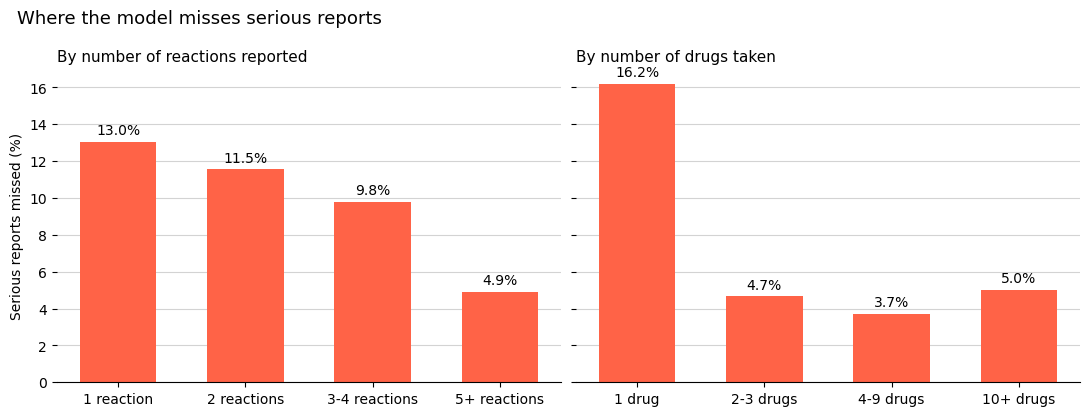

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)

for ax, table, title in [
    (axes[0], by_reactions, "By number of reactions reported"),
    (axes[1], by_drugs, "By number of drugs taken"),
]:
    ax.bar(table.index, table["miss_rate"] * 100, width=0.6, color="tomato")
    for i, value in enumerate(table["miss_rate"] * 100):
        ax.text(i, value + 0.4, f"{value:.1f}%", ha="center", fontsize=10)

    ax.set_title(title, loc="left", fontsize=11)
    ax.grid(axis="y", color="lightgrey", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)

axes[0].set_ylabel("Serious reports missed (%)")
fig.suptitle("Where the model misses serious reports", x=0.02, ha="left", fontsize=13)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "error_miss_rate.png", dpi=150, bbox_inches="tight")
plt.show()

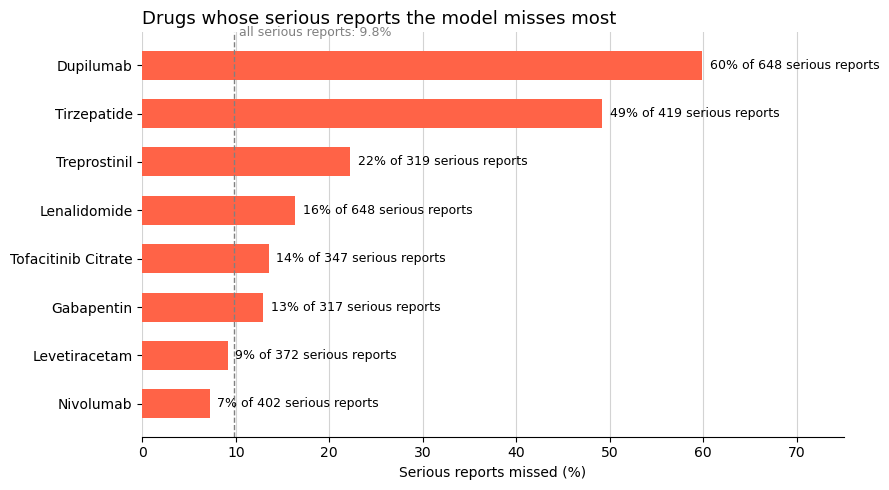

In [9]:
top_drugs = drug_misses.head(8).iloc[::-1]
overall = missed.sum() / y_test.sum()

fig, ax = plt.subplots(figsize=(9, 5))

ax.barh(top_drugs.index, top_drugs["miss_rate"] * 100, height=0.6, color="tomato")
for i, (value, total) in enumerate(zip(top_drugs["miss_rate"] * 100, top_drugs["serious_reports"])):
    ax.text(value + 0.8, i, f"{value:.0f}% of {total} serious reports", va="center", fontsize=9)

ax.axvline(overall * 100, color="grey", linestyle="--", linewidth=1)
ax.text(overall * 100 + 0.5, len(top_drugs) - 0.4, f"all serious reports: {overall:.1%}", color="grey", fontsize=9)

ax.set_xlabel("Serious reports missed (%)")
ax.set_xlim(0, 75)
ax.set_title("Drugs whose serious reports the model misses most", loc="left", fontsize=13)
ax.grid(axis="x", color="lightgrey", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "error_by_drug.png", dpi=150, bbox_inches="tight")
plt.show()

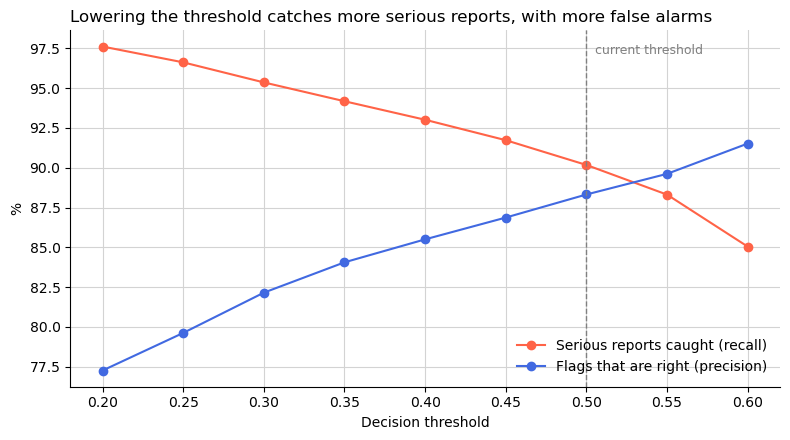

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(thresholds.index, thresholds["recall"] * 100, marker="o", color="tomato", label="Serious reports caught (recall)")
ax.plot(thresholds.index, thresholds["precision"] * 100, marker="o", color="royalblue", label="Flags that are right (precision)")
ax.axvline(THRESHOLD, color="grey", linestyle="--", linewidth=1)
ax.text(THRESHOLD + 0.005, ax.get_ylim()[1] - 1.5, "current threshold", color="grey", fontsize=9)

ax.set_xlabel("Decision threshold")
ax.set_ylabel("%")
ax.set_title("Lowering the threshold catches more serious reports, with more false alarms", loc="left", fontsize=12)
ax.grid(color="lightgrey", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.legend(loc="lower right", frameon=False)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "error_threshold.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
explainer = shap.TreeExplainer(model)
numeric = ["age_years", "n_drugs", "n_other_drugs", "n_reactions", "n_other_reactions"]

missed_positions = np.flatnonzero(missed)
most_confident = missed_positions[np.argsort(probabilities[missed_positions])[:3]]

for position in most_confident:
    x = X_test.iloc[[position]].astype(float)
    event = x.iloc[0]
    values = pd.Series(explainer.shap_values(x)[0], index=FEATURES)

    present = [
        f for f in FEATURES
        if (f in numeric and event[f] > 0) or (f not in numeric and event[f] == 1)
    ]
    present = [f for f in present if not (f == "age_years" and pd.isna(event[f]))]

    chosen = values[present]
    chosen = chosen.reindex(chosen.abs().sort_values(ascending=False).index).head(5)

    print(f"Missed serious report {int(test.iloc[position]['primaryid'])}: predicted {probabilities[position]:.1%}")
    for feature, value in chosen.items():
        direction = "towards serious" if value > 0 else "towards non-serious"
        shown = event[feature] if feature in numeric else "present"
        print(f"   {labels[feature]} ({shown}): {direction} ({value:+.2f})")
    print()

Missed serious report 249641902: predicted 0.6%
   Reaction: No adverse event (present): towards non-serious (-2.43)
   Reaction: Device defective (present): towards non-serious (-0.83)
   Reaction: Incorrect dose administered (present): towards non-serious (-0.53)
   Reaction: Needle issue (present): towards non-serious (-0.45)
   Age (46.0): towards serious (+0.30)

Missed serious report 248579014: predicted 0.7%
   Somatropin (present): towards non-serious (-1.66)
   Reaction: Drug dose omission by device (present): towards non-serious (-1.37)
   Reaction: Device leakage (present): towards non-serious (-0.89)
   Reaction: Device mechanical issue (present): towards non-serious (-0.46)
   Number of drugs (1.0): towards non-serious (-0.37)

Missed serious report 249665031: predicted 0.8%
   Dupilumab (present): towards non-serious (-2.39)
   Apremilast (present): towards non-serious (-1.29)
   Number of drugs (3.0): towards serious (+0.48)
   Adalimumab (present): towards non-serious (

In [12]:
thresholds.round(4).to_csv(MODELS_DIR / "serious_threshold_tradeoff.csv")
print("Saved models/serious_threshold_tradeoff.csv")
print("Saved reports/figures/error_miss_rate.png, error_by_drug.png and error_threshold.png")

Saved models/serious_threshold_tradeoff.csv
Saved reports/figures/error_miss_rate.png, error_by_drug.png and error_threshold.png
